In [92]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [93]:
df = pd.read_csv("/content/AB_NYC_2019.csv.zip")

In [94]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [95]:
df.tail()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2
48894,36487245,Trendy duplex in the very heart of Hell's Kitchen,68119814,Christophe,Manhattan,Hell's Kitchen,40.76404,-73.98933,Private room,90,7,0,NaN,NaN,1,23


In [96]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [97]:
df.duplicated().sum()

np.int64(0)

In [98]:
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [99]:
df.shape

(48895, 16)

In [100]:
df.drop(columns=['last_review'],inplace=True)

In [101]:
df['reviews_per_month'] = df['reviews_per_month'].fillna(df['reviews_per_month'].mean())

In [102]:
df=df.drop(columns=["id","name","host_id","host_name","calculated_host_listings_count"])

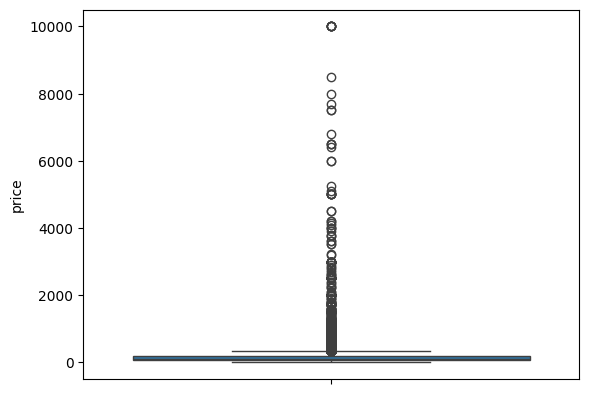

In [103]:
# Univariate Analysis
sns.boxplot(df['price'])
plt.show()

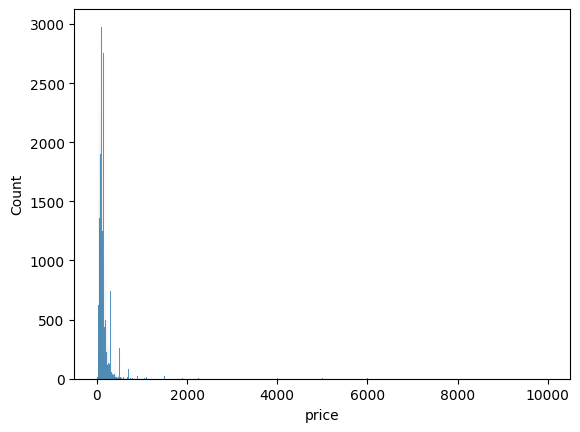

In [104]:
sns.histplot(df['price'])
plt.show()

In [105]:
for col in ['price']:
  Q1 = df[col].quantile(0.95)

In [106]:
#  Apply 95th percentile capping/trimming strategy
price = df['price'].quantile(0.95)
print(f'95th Percentile Price: ${price}')
df_filtered = df[
    (df['price'] > 0)
    & (df['price'] <= price)
    & (df['minimum_nights'] <= 365)
].copy()

print('Dataset shape after outlier removal:', df_filtered.shape)

95th Percentile Price: $355.0
Dataset shape after outlier removal: (46430, 10)


In [107]:
#Address High Cardinality
if 'neighbourhood' in df_filtered.columns:
  df_filtered.drop(columns=['neighbourhood'], inplace=True)

#  One-Hot Encoding with drop_first=True to avoid the Dummy Variable Trap
df_encoded = pd.get_dummies(
    df_filtered, columns=['neighbourhood_group', 'room_type'], drop_first=True
)

print('Encoded Dataset Shape:', df_encoded.shape)
display(df_encoded.head())

Encoded Dataset Shape: (46430, 13)


,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,availability_365,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,149,1,9,0.210000,365,True,False,False,False,True,False
1,40.75362,-73.98377,225,1,45,0.380000,355,False,True,False,False,False,False
2,40.80902,-73.94190,150,3,0,1.373221,365,False,True,False,False,True,False
3,40.68514,-73.95976,89,1,270,4.640000,194,True,False,False,False,False,False
4,40.79851,-73.94399,80,10,9,0.100000,0,False,True,False,False,False,False


In [108]:
from sklearn.model_selection import train_test_split

#Separate features (X) and target variable (y)
X = df_encoded.drop(columns=['price'])
y = df_encoded['price']
#Split the data into 80% Training and 20% Testing sets with a fixed random_state
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'Training Set Shape: {X_train.shape}')
print(f'Testing Set Shape: {X_test.shape}')

Training Set Shape: (37144, 12)
Testing Set Shape: (9286, 12)


In [109]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#Initialize and fit the Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

#Generate price predictions on testing data
y_pred = lr_model.predict(X_test)

#Calculate evaluation metrics
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print('--- Model Evaluation Metrics ---')
print(f'R-Squared (R2) Score: {r2:.4f}')
print(f'Mean Absolute Error (MAE): ${mae:.2f}')
print(f'Root Mean Squared Error (RMSE): ${rmse:.2f}')

--- Model Evaluation Metrics ---
R-Squared (R2) Score: 0.4627
Mean Absolute Error (MAE): $38.30
Root Mean Squared Error (RMSE): $52.46


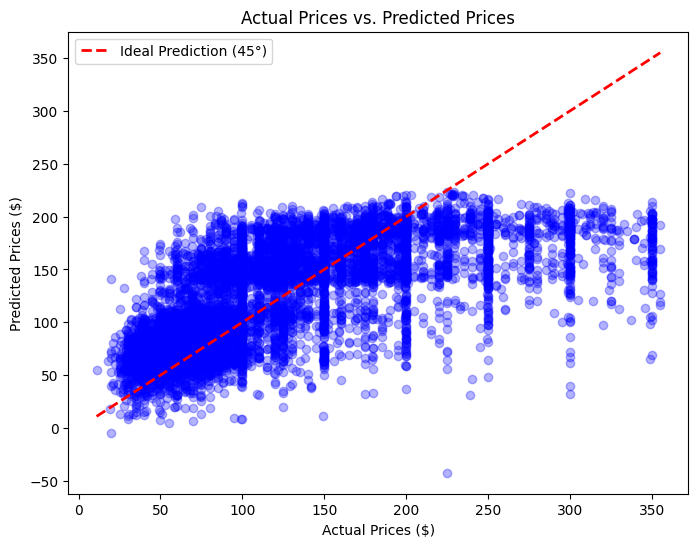

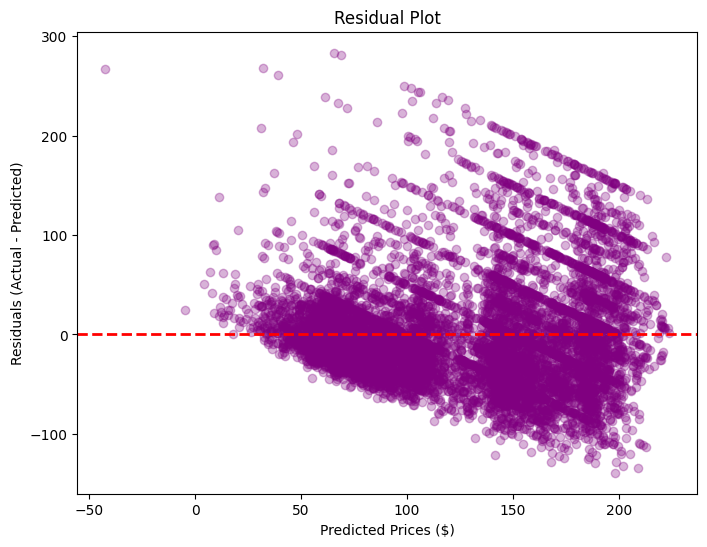

In [110]:
#Scatter plot of Actual Prices vs. Predicted Prices
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='blue')
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--',
    linewidth=2,
    label='Ideal Prediction (45°)',
)
plt.xlabel('Actual Prices ($)')
plt.ylabel('Predicted Prices ($)')
plt.title('Actual Prices vs. Predicted Prices')
plt.legend()
plt.show()

#Residual Plot (Errors vs. Predicted values)
residuals = y_test - y_pred
plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.3, color='purple')
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)
plt.xlabel('Predicted Prices ($)')
plt.ylabel('Residuals (Actual - Predicted)')
plt.title('Residual Plot')
plt.show()